In [2]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
from search_core import load_model, embed, preprocess_query, to_model_input, search

os.makedirs("index", exist_ok=True)

## Task 1

In [3]:
cat = ["basketball", "bread", "circle", "clock", "flower", "house", "moon", "sandwich", "square", "sun"]
held = ["train", "airplane"]
rng = np.random.default_rng(42)

def load(name):
    return np.load(f"Data/raw/full_numpy_bitmap_{name}.npy", mmap_mode="r")

g_img, g_lab, q_img, q_lab, h_img, h_lab = [], [], [], [], [], []

for name in cat:
    data = load(name)
    idx = rng.choice(len(data), 500, replace=False)       # ONE draw, so gallery and queries never overlap
    g_img.append(data[np.sort(idx[:450])]); g_lab += [name] * 450
    q_img.append(data[np.sort(idx[450:])]); q_lab += [name] * 50

for name in held:
    data = load(name)
    idx = np.sort(rng.choice(len(data), 450, replace=False))
    h_img.append(data[idx]); h_lab += [name] * 450

gallery_images = np.concatenate(g_img).reshape(-1, 28, 28); gallery_labels = np.array(g_lab)
query_images   = np.concatenate(q_img).reshape(-1, 28, 28); query_labels   = np.array(q_lab)
held_images    = np.concatenate(h_img).reshape(-1, 28, 28); held_labels    = np.array(h_lab)

np.savez_compressed("Data/subset.npz",
                    gallery_images=gallery_images, gallery_labels=gallery_labels,
                    query_images=query_images, query_labels=query_labels,
                    held_images=held_images, held_labels=held_labels)
print(gallery_images.shape, query_images.shape, held_images.shape)

FileNotFoundError: [Errno 2] No such file or directory: 'Data/raw/full_numpy_bitmap_basketball.npy'

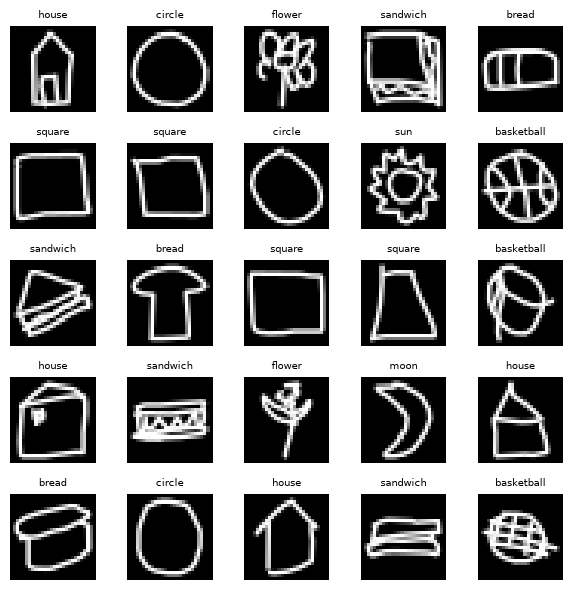

In [ ]:
fig, ax = plt.subplots(5, 5, figsize=(6, 6))
for a, i in zip(ax.ravel(), rng.choice(len(gallery_images), 25, replace=False)):
    a.imshow(gallery_images[i], cmap="gray"); a.set_title(gallery_labels[i], fontsize=7); a.axis("off")
plt.tight_layout(); plt.show()

## Task 2

In [ ]:
model = load_model()
gallery_vecs = embed(model, gallery_images)

assert gallery_vecs.shape == (4500, 1280), gallery_vecs.shape
assert np.allclose(np.linalg.norm(gallery_vecs, axis=1), 1.0, atol=1e-4)

np.save("index/embeddings.npy", gallery_vecs)
np.save("index/gallery_images.npy", gallery_images)
np.save("index/gallery_labels.npy", gallery_labels)      
print(gallery_vecs.shape)

(4500, 1280)


## Task 3

In [ ]:
from PIL import Image

def check_query(path):
    img = Image.open(path)
    small = preprocess_query(img)
    fig, ax = plt.subplots(1, 3, figsize=(8, 3))
    ax[0].imshow(img); ax[0].set_title("raw query")
    if small is not None:
        ax[1].imshow(small, cmap="gray")
    ax[1].set_title("preprocessed")
    ax[2].imshow(gallery_images[rng.integers(len(gallery_images))], cmap="gray"); ax[2].set_title("gallery doodle")
    for a in ax: a.axis("off")
    plt.show()

# for p in ["paint_drawing.png", "phone_photo.jpg", "webcam_frame.png"]:
#     check_query(p)

## Task 4: Evaluate

In [ ]:
def precision_at_k(queries, q_labels, gallery, g_labels, k):
    """Per-query share of the top k results with the query's category (labels used only here)."""
    return np.array([np.mean(g_labels[search(q, gallery, k)[0]] == label)
                     for q, label in zip(queries, q_labels)])

def raw_pixels(images):
    x = np.asarray(images, "float32").reshape(len(images), -1)
    return x / np.linalg.norm(x, axis=1, keepdims=True)

def best_threshold(s_in, s_out):
    """Score t (accept if >= t) that best separates in-index from held-out."""
    cands = np.sort(np.concatenate([s_in, s_out]))
    gap = [(s_in >= t).mean() - (s_out >= t).mean() for t in cands]
    return float(cands[np.argmax(gap)])

query_vecs = embed(model, query_images)
held_vecs = embed(model, held_images)

methods = {
    "Raw pixels": (raw_pixels(query_images), raw_pixels(gallery_images)),
    "Your model": (query_vecs, gallery_vecs),
    "Your model, inverted colors": (embed(model, query_images, invert=True),
                                    embed(model, gallery_images, invert=True)),
}
table = ["| Method | precision@5 | precision@25 |", "|---|---|---|"]
for name, (q, g) in methods.items():
    p5, p25 = (precision_at_k(q, query_labels, g, gallery_labels, k).mean() for k in (5, 25))
    table.append(f"| {name} | {p5:.3f} | {p25:.3f} |")
print("\n".join(table))

| Method | precision@5 | precision@25 |
|---|---|---|
| Raw pixels | 0.608 | 0.550 |
| Your model | 0.873 | 0.829 |
| Your model, inverted colors | 0.878 | 0.849 |


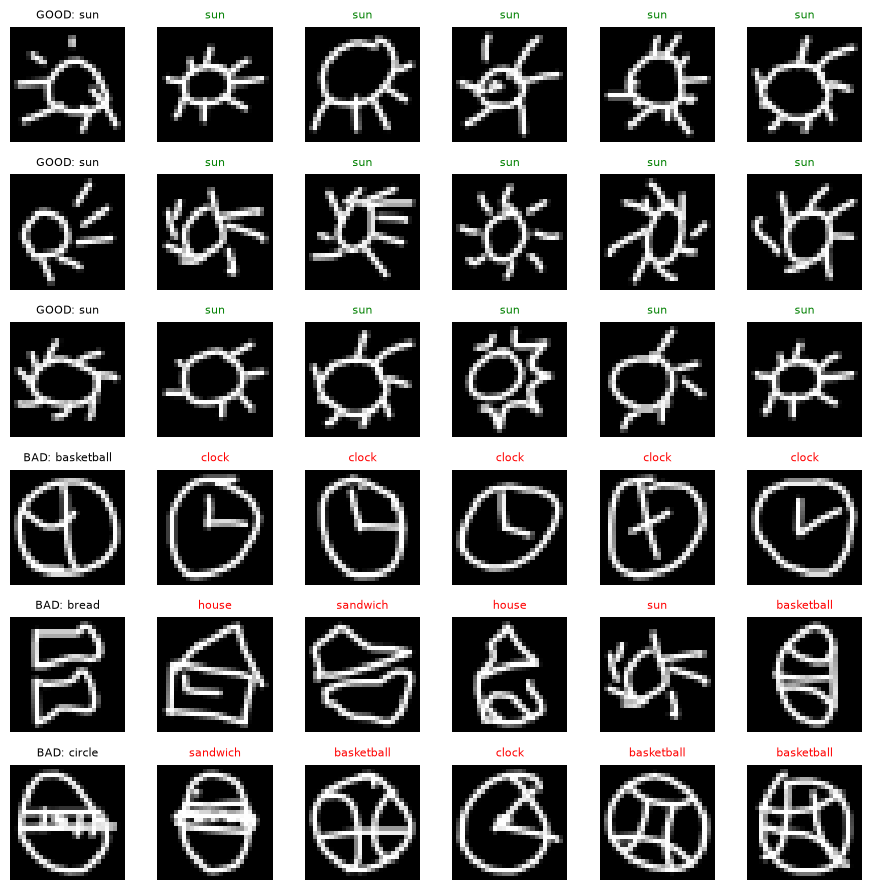

In [ ]:
# Visual check: 3 best and 3 worst queries by precision@5
p5 = precision_at_k(query_vecs, query_labels, gallery_vecs, gallery_labels, 5)
order = np.argsort(p5, kind="stable")
picks = list(order[-3:]) + list(order[:3])

fig, ax = plt.subplots(6, 6, figsize=(9, 9))
for row, i in enumerate(picks):
    ax[row, 0].imshow(query_images[i], cmap="gray")
    ax[row, 0].set_title(f"{'GOOD' if row < 3 else 'BAD'}: {query_labels[i]}", fontsize=8)
    for col, j in enumerate(search(query_vecs[i], gallery_vecs, 5)[0], 1):
        ax[row, col].imshow(gallery_images[j], cmap="gray")
        ax[row, col].set_title(gallery_labels[j], fontsize=8,
                               color="g" if gallery_labels[j] == query_labels[i] else "r")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("index/visual_check.png"); plt.show()

In [4]:
pip install streamlit-drawable-canvas

Note: you may need to restart the kernel to use updated packages.
